## Initialization

In [1]:
import sys
sys.path.append('../src') # add the source code to the path

# These are the main files in MinScaffold/src/
# BUT we won't use them here

import Driver
import Geometry
import Scaffold

# These libraries are used throughout the code

import math
import numpy as np
from random import random
import networkx as nx
import pickle as pk
import matplotlib.pyplot as plt
import shapely
from shapely.geometry import Polygon
import geopandas as gpd
import pandas as pd

## My data: the grocery stores
# 

In [2]:
# All the distance matrices to consider
# ANANYA: For our purposes, we only use "geodesic" and "walk"
# and will not compute the persistent homology
#
# Nor do we read in a matrix of distances; instead, use the "buffer" function

dist_type_list = ['geodesic','walk','drive_osm','drive_gmaps_TrafUnaware']

dist_type = dist_type_list[0]

### (1a) Read in resource locations; organize Lat,Long coordinates

Replace with your own paths



In [3]:
# Replace with whereever you are keeping data
data_topdir = '../../tda-resources-dallas/Dallas/'

#
# Resource of interest
resource_dir  = data_topdir+'Food access_updated/'
resource_fname = 'geo_export_872fcb6c-fbde-4264-ae77-8858a604ed0e.shp'

# ZIP codes: good for visualization
zip_dir = data_topdir+'Zip/'
zip_fname = 'dal_tx_zip.shp'

# Population; Census blocks or others
block_dir = data_topdir + 'Block/'
block_fname = 'dal_tx_block.shp'


### 1(b) Make a list of "epsilons"; i.e. distance values

In [4]:
# The values in epsList would USUALLY be round-trip distances/times between resource sites.
# To interpret this number as a round-trip distance from somewhere else to a resource site, divide by 2.
# Why? The hypothetical person at the midpoint between two resource sites (RS), only need to travel 
# half the distance to get to one of the sites.
#
# So eps = 120 min here, means "round trip distance to an RS = 60 min" 
epsList = np.arange(1,121,2)

In [5]:
epsList

array([  1,   3,   5,   7,   9,  11,  13,  15,  17,  19,  21,  23,  25,
        27,  29,  31,  33,  35,  37,  39,  41,  43,  45,  47,  49,  51,
        53,  55,  57,  59,  61,  63,  65,  67,  69,  71,  73,  75,  77,
        79,  81,  83,  85,  87,  89,  91,  93,  95,  97,  99, 101, 103,
       105, 107, 109, 111, 113, 115, 117, 119])

## (2) SKIP: Use MinScaffold to compute homology over filtration

We get rid of all this code here: will only use geodesic distance buffers around each resource site

## (3) Find unserved area for each eps value.  Calculate population in unserved area.

In [6]:
# For names/locations of data files, see first few cells
block_df = gpd.read_file(block_dir+block_fname)
groc_df  = gpd.read_file(resource_dir+resource_fname)
zip_df = gpd.read_file(zip_dir+zip_fname)

In [7]:

sqm_to_sqmi_convert = 2589988

# Assuming "ALAND' and "POP20" are accurate:
block_df['PopDens']=block_df['POP20']/block_df['ALAND20']*sqm_to_sqmi_convert

In [8]:
# Coordinate systems
meters_per_mile = 1609.34
crs = {
    'census': 'EPSG:4269'  , # degrees - used by Census
    'projected': 'EPSG:3083',         # projected; needed for maup
    'area'  : 'ESRI:102003', # meters
    'length': 'ESRI:102005', # meters
}
'''
EPSG:3083
Coordinate System: 	
Cartesian 2D CS. Axes: easting, northing (X,Y). 
Orientations: east, north. UoM: m.Open
Base CRS: 	
NAD83Open
Conversion: 	
Texas Centric Albers Equal Area
'''

'\nEPSG:3083\nCoordinate System: \t\nCartesian 2D CS. Axes: easting, northing (X,Y). \nOrientations: east, north. UoM: m.Open\nBase CRS: \t\nNAD83Open\nConversion: \t\nTexas Centric Albers Equal Area\n'

In [9]:
# Project all into CRS
block_df.geometry = block_df.geometry.to_crs(crs['projected'])
groc_df.geometry = groc_df.geometry.to_crs(crs['projected'])

In [10]:
geo_walk_conversion_rate = 1.14 # adjustment factor to compensate for walking distance being longer than geodesic distance

walk_speed=1.38

In [11]:
# Calculate population in holes for a few indices
block_df_union = block_df.union_all()

# do we want to do visuals?
do_visuals = False

allCycles = pd.DataFrame(data=[], columns=['poly','geometry'])

indices = range(len(epsList))
for i in indices:
    print(epsList[i])
    # Geodesic distance is measured in meters. 
    # Walk speed is meters/second. 
    # Divide by 4 because (1) the distance in a PH calculation is round-trip travel between
    #   two resource sites: a hypothetical person at the midpoint, has only 1/2 that distance 
    #   to travel, to get to one of the resource sites.
    #   (2) Round-trip vs. one-way (another factor of 1/2). For example: to capture the service area within 
    #   a 1 km round-trip, we need a geodesic circle of radius 0.5 km.
    if dist_type == 'walk':
        radius_serv_area = epsList[i] * 60 * walk_speed / (4 * geo_walk_conversion_rate)
    elif dist_type == 'geodesic':
        radius_serv_area = epsList[i] * 60 * walk_speed / 4
    print(radius_serv_area)

    # Create service areas of all grocery stores, with the given radius
    service_areas = groc_df.geometry.buffer(radius_serv_area)
    service_areas_all = service_areas.union_all()
    service_areas_in_cnty = block_df_union.intersection(service_areas_all)

    # The rest of the area NOT included in the service areas
    county_with_holes = block_df_union.difference(service_areas_in_cnty)

    if do_visuals:
        d = {'eps': [epsList[i]], 'geometry': county_with_holes}
        gpd.GeoDataFrame(d,crs=crs['projected']).plot()
    #county_with_holes_union = county_with_holes

    # Keep each of the "swiss cheese" shapes
    min_cycle_hole_df = pd.DataFrame(data=[], columns=['eps','which_cycle','poly','geometry'])

    # This is unneccessary here. 
    #  When actually getting multiple cycles expressed as vertex lists,
    #   we have to go through each one, reconstruct the cycle, intersect w/ the exterior of service areas to 
    #   get polygons. 
    # Here, we have a single polygon or multipolygon or each eps.
    # 
    newrow = pd.DataFrame(data={'which_cycle':[0] , 'poly':[0], 'geometry': county_with_holes})
    min_cycle_hole_df = pd.concat([min_cycle_hole_df,newrow],ignore_index=True)

    min_cycle_hole_df['eps']=epsList[i]

    allCycles = pd.concat([allCycles,min_cycle_hole_df],ignore_index=True)

1
20.7
3
62.099999999999994
5
103.49999999999999
7
144.89999999999998
9
186.29999999999998
11
227.7
13
269.09999999999997
15
310.5
17
351.9
19
393.29999999999995
21
434.7
23
476.09999999999997
25
517.5
27
558.9
29
600.3
31
641.6999999999999
33
683.0999999999999
35
724.5
37
765.9
39
807.3
41
848.6999999999999
43
890.0999999999999
45
931.4999999999999
47
972.9
49
1014.3
51
1055.6999999999998
53
1097.1
55
1138.5
57
1179.8999999999999
59
1221.3
61
1262.6999999999998
63
1304.1
65
1345.5
67
1386.8999999999999
69
1428.3
71
1469.6999999999998
73
1511.1
75
1552.4999999999998
77
1593.8999999999999
79
1635.3
81
1676.6999999999998
83
1718.1
85
1759.4999999999998
87
1800.8999999999999
89
1842.3
91
1883.6999999999998
93
1925.1
95
1966.4999999999998
97
2007.8999999999999
99
2049.2999999999997
101
2090.7
103
2132.1
105
2173.5
107
2214.8999999999996
109
2256.2999999999997
111
2297.7
113
2339.1
115
2380.5
117
2421.8999999999996
119
2463.2999999999997


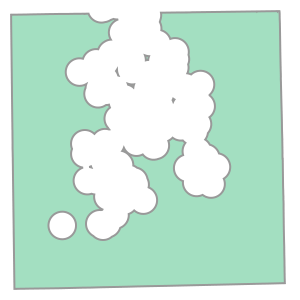

In [12]:
county_with_holes

In [13]:
# Multi-index, if more than one polygon per eps value
tempdf=allCycles.set_index(['eps','which_cycle'])

In [17]:
tempdf.head()

,,poly,geometry
eps,which_cycle,,
1.0,0,0,POLYGON ((1777532.8197330425 7610722.731713578...
3.0,0,0,POLYGON ((1777532.8197330425 7610722.731713578...
5.0,0,0,POLYGON ((1777532.8197330425 7610722.731713578...
7.0,0,0,POLYGON ((1777532.8197330425 7610722.731713578...
9.0,0,0,POLYGON ((1777532.8197330425 7610722.731713578...


In [14]:
min_cycle_hole_gdf = gpd.GeoDataFrame(tempdf,geometry=tempdf['geometry'])

In [ ]:
# POPULATION INSIDE HOLE
#
# This may go through ALL holes with any filtration value
# I kept intermediate values (like intersection area, etc.) in case we want to look more closely
#    at the results
# Have not attempted to optimize in speed or efficiency
# 
interarea = pd.Series(index=min_cycle_hole_gdf.index)
interpop = pd.Series(index=min_cycle_hole_gdf.index)

for cycleind,cyclerow in min_cycle_hole_gdf.iterrows():
    print(cycleind)
    #print(cyclerow)
    # For a single hole, find all non-empty intersections with Census blocks
    mytemp=cyclerow['geometry'].intersection(block_df['geometry'])
    actualInt = mytemp[~mytemp.is_empty]

    actualInt = gpd.GeoDataFrame(data=actualInt)
    # Actual area of intersection
    actualInt['intarea']=actualInt.geometry.area
    
    # Join with Census blocks: area+plus total pop
    # If we are ever unsure Re: area, can also recompute from available geometry
    actualInt = actualInt.join(block_df[['POP20','ALAND20']])
    # Assume pop density uniform through block
    actualInt['InterPop'] = actualInt['POP20']*actualInt['intarea']/actualInt['ALAND20']

    interpop[cycleind]=actualInt['InterPop'].sum()
    interarea[cycleind]=actualInt['intarea'].sum()
    
    if False:
        # This is time and space consuming. 
        # Iterate through Census blocks. For each track area, intersection area, populations
        actualInt=pd.DataFrame(actualInt)
        blkarea = pd.Series(index=actualInt.index)
        intarea = pd.Series(index=actualInt.index)
        blkpop = pd.Series(index=actualInt.index)

        for index, value in actualInt.iterrows():
            blkarea[index]=block_df.loc[index].geometry.area
            intarea[index]=actualInt.loc[index].geometry.area
            blkpop[index]=block_df.loc[index]['POP20']

        # Put back into "actualInt" dataframe
        actualInt['Block area']=blkarea
        actualInt['Intersection area']=intarea
        actualInt['Block pop']=blkpop

        actualInt['Intersection pop']= blkpop*intarea/blkarea

        interpop[cycleind]=actualInt['Intersection pop'].sum()
        interarea[cycleind]=actualInt['Intersection area'].sum()

min_cycle_hole_gdf['Population']= interpop
min_cycle_hole_gdf['Area']= interarea


(1.0, 0)
(3.0, 0)
(5.0, 0)
(7.0, 0)
(9.0, 0)
(11.0, 0)
(13.0, 0)
(15.0, 0)
(17.0, 0)


In [ ]:
#min_cycle_hole_gdf

In [ ]:
# Total # of people inconvenienced for this specific filtration value
min_cycle_hole_gdf['Population'].groupby(['eps']).sum()